# Modelagem Matemática e Computacional: redistribuição da frota de ônibus

**Case:** Citizen Assist AI (GS 2026.2, FIAP). **Pergunta:** a frota de ônibus está bem distribuída entre as regiões da cidade? Se não, como redistribuir e o que se ganha?

**Cidade e regiões:** Belo Horizonte, dividida em 4 áreas de operação (consórcios): Pampulha (801), BH Leste (802), Dez (803) e Dom Pedro II (804).

**Dados reais:** Prefeitura de Belo Horizonte / BHTRANS, agosto de 2026 (detalhes em `dados/FONTES.md`).


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "modelo" else Path.cwd()
sys.path.insert(0, str(RAIZ / "modelo"))
import modelo_frota as mf

df = mf.carregar_dados()
df[["regiao", "onibus_cadastrados", "onibus_atuais", "passageiros_dia_util", "viagens_dia_util", "km_dia_util"]]

,regiao,onibus_cadastrados,onibus_atuais,passageiros_dia_util,viagens_dia_util,km_dia_util
0,Pampulha,683,836,195173.3,7381.4,132307.3
1,BH Leste,709,778,206960.5,6843.0,120165.8
2,Dez,665,752,222390.8,6358.9,125259.3
3,Dom Pedro II,700,500,130083.7,3485.2,73770.6


## 1. Situação atual

A *carga* de uma região é a quantidade de passageiros por dia útil dividida pelo número de ônibus que operam nela. Se a carga varia muito entre regiões, alguns ônibus ficam sobrecarregados enquanto outros ficam folgados.

In [2]:
demanda = df["passageiros_dia_util"].to_numpy()
atuais = df["onibus_atuais"].to_numpy()
antes = mf.indicadores(demanda, atuais)
pd.Series(antes, name="situação atual").round(3)

carga_media      263.844
carga_maxima     295.732
carga_minima     233.461
razao_max_min      1.267
coef_variacao      0.084
Name: situação atual, dtype: float64

## 2. O modelo

**Variáveis:** $x_i$ = número de ônibus na região $i$ após a redistribuição (inteiro).
**Dados:** $d_i$ = passageiros por dia útil, $x^0_i$ = ônibus que operam hoje, $N=\sum x^0_i$ (a frota total não muda).
**Alvo:** $a_i = N\, d_i / \sum_j d_j$ (frota proporcional à demanda).

$$\min \sum_i |x_i - a_i| \quad\text{sujeito a}\quad \sum_i x_i = N,\;\; (1-f)\,x^0_i \le x_i \le (1+f)\,x^0_i,\;\; x_i\in\mathbb{Z}$$

O módulo $|\cdot|$ vira restrições lineares com variáveis auxiliares $t_i \ge |x_i - a_i|$. A folga $f$ limita quantos ônibus cada região pode ganhar ou perder (por limites de garagem, contrato e operação). O problema é de **programação linear inteira**, resolvido com `scipy.optimize.milp`.

In [3]:
proposta = mf.comparar(df, folga=0.15)
proposta

,regiao,passageiros_dia_util,onibus_atuais,onibus_propostos,variacao,pass_por_onibus_antes,pass_por_onibus_depois,km_por_onibus_antes,km_por_onibus_depois
0,Pampulha,195173.3,836,741,-95,233.5,263.4,158.3,178.6
1,BH Leste,206960.5,778,786,8,266.0,263.3,154.5,152.9
2,Dez,222390.8,752,845,93,295.7,263.2,166.6,148.2
3,Dom Pedro II,130083.7,500,494,-6,260.2,263.3,147.5,149.3


In [4]:
novos = proposta["onibus_propostos"].to_numpy()
depois = mf.indicadores(demanda, novos)
resumo = pd.DataFrame({"antes": antes, "depois": depois}).round(3)
resumo["mudança"] = (resumo["depois"] - resumo["antes"]).round(3)
resumo

,antes,depois,mudança
carga_media,263.844,263.303,-0.541
carga_maxima,295.732,263.392,-32.340
carga_minima,233.461,263.184,29.723
razao_max_min,1.267,1.001,-0.266
coef_variacao,0.084,0.000,-0.084


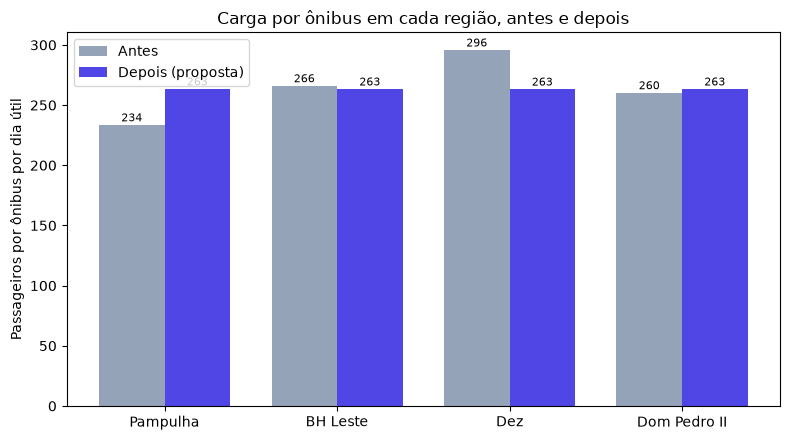

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(proposta))
largura = 0.38
ax.bar(x - largura / 2, proposta["pass_por_onibus_antes"], largura, label="Antes", color="#94a3b8")
ax.bar(x + largura / 2, proposta["pass_por_onibus_depois"], largura, label="Depois (proposta)", color="#4f46e5")
ax.set_xticks(x, proposta["regiao"])
ax.set_ylabel("Passageiros por ônibus por dia útil")
ax.set_title("Carga por ônibus em cada região, antes e depois")
ax.legend()
for i, (a, d) in enumerate(zip(proposta["pass_por_onibus_antes"], proposta["pass_por_onibus_depois"])):
    ax.text(i - largura / 2, a + 3, f"{a:.0f}", ha="center", fontsize=8)
    ax.text(i + largura / 2, d + 3, f"{d:.0f}", ha="center", fontsize=8)
fig.tight_layout()
(RAIZ / "resultados").mkdir(exist_ok=True)
fig.savefig(RAIZ / "resultados" / "comparativo_antes_depois.png", dpi=150)
proposta.to_csv(RAIZ / "resultados" / "tabela_resultados.csv", index=False, encoding="utf-8")
plt.show()

## 3. Sensibilidade: quanto remanejar?

Quanto maior a folga, maior o ganho de equilíbrio, mas mais ônibus mudam de região. A tabela mostra esse custo-benefício.

In [6]:
sens = mf.sensibilidade(df)
sens

,folga,onibus_remanejados,coef_variacao,razao_max_min,carga_maxima
0,0.00,0,0.0839,1.267,295.7
1,0.05,47,0.0480,1.145,281.5
2,0.10,85,0.0140,1.040,268.6
3,0.15,101,0.0003,1.001,263.4
4,0.20,101,0.0003,1.001,263.4
5,0.30,101,0.0003,1.001,263.4
6,0.50,101,0.0003,1.001,263.4


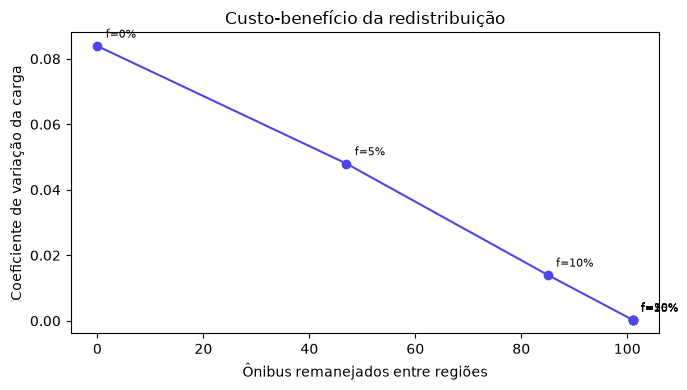

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sens["onibus_remanejados"], sens["coef_variacao"], marker="o", color="#4f46e5")
for _, linha in sens.iterrows():
    ax.annotate(f"f={linha['folga']:.0%}", (linha["onibus_remanejados"], linha["coef_variacao"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Ônibus remanejados entre regiões")
ax.set_ylabel("Coeficiente de variação da carga")
ax.set_title("Custo-benefício da redistribuição")
fig.tight_layout()
fig.savefig(RAIZ / "resultados" / "sensibilidade.png", dpi=150)
sens.to_csv(RAIZ / "resultados" / "sensibilidade.csv", index=False, encoding="utf-8")
plt.show()

## 4. Checagem do custo operacional

Mover ônibus muda quantos quilômetros cada ônibus precisa rodar para manter o mesmo serviço. Se a proposta só empurrasse o problema para a quilometragem, ela não seria boa.

In [8]:
proposta[["regiao", "km_por_onibus_antes", "km_por_onibus_depois"]]

,regiao,km_por_onibus_antes,km_por_onibus_depois
0,Pampulha,158.3,178.6
1,BH Leste,154.5,152.9
2,Dez,166.6,148.2
3,Dom Pedro II,147.5,149.3


In [9]:
ganho = 1 - depois["coef_variacao"] / antes["coef_variacao"]
movidos = int(np.clip(proposta["variacao"], 0, None).sum())
pct = movidos / atuais.sum()
print(f"Desigualdade de carga (coef. de variação): {antes['coef_variacao']:.3f} -> {depois['coef_variacao']:.4f} ({ganho:.0%} menor)")
print(f"Carga do ônibus mais sobrecarregado: {antes['carga_maxima']:.0f} -> {depois['carga_maxima']:.0f} passageiros/dia")
print(f"Ônibus remanejados: {movidos} de {atuais.sum()} ({pct:.1%} da frota)")

Desigualdade de carga (coef. de variação): 0.084 -> 0.0003 (100% menor)
Carga do ônibus mais sobrecarregado: 296 -> 263 passageiros/dia
Ônibus remanejados: 101 de 2866 (3.5% da frota)


## 5. Conclusão e limitações

Veja `docs/ANALISE_E_CONCLUSAO.md` para a interpretação completa. Limitações principais: o modelo trata todas as regiões e ônibus como equivalentes; usa passageiros por dia útil de um único mês; o MCO não inclui passageiros das linhas de bloqueio das estações BHBUS e MOVE; e mover ônibus entre consórcios envolve contratos e garagens, por isso a folga é um parâmetro, não uma certeza.